## ReLU MLP Single-Seed Training with Optimizer-State Snapshots

Training-only counterpart of `scratch.ipynb`. It trains one seed of a plain ReLU MLP on
depth-5 COB-ODT data with the same hyperparameters, but uses
`run_single_relu_seed_replayable`, which differs from `run_single_relu_seed` in two ways:

1. **Optimizer state is snapshotted.** At every snapshot epoch the Adam moments and step
   counters (or SGD momentum buffers), the learning rate in force, and the mini-batch
   permutation state are stored alongside the model state. `replay_epoch_from_snapshot`
   can then re-run any snapshot epoch step-for-step and return the per-step mini-batch
   gradients, parameter updates, and Adam per-coordinate step sizes.
2. **No data arrays are stored.** `seed_result["data"]` is replaced by
   `seed_result["data_spec"]`; call `regenerate_seed_result_data(seed_result)` to rebuild
   the train/eval split from its seed. Pickles are correspondingly small.

Seeds, initialisation, and the training arithmetic are identical to `run_single_relu_seed`,
so checkpoints match bit-for-bit for the same arguments (no shuffling, as in the current
`train_relu_mlp`).

`OPTIMIZER` also accepts `"sgd_adam"`, a hybrid that trains the first
`SGD_ADAM_SPLIT_LAYER` hidden layers with SGD-with-momentum and everything after them with
AdamW. The motivation is that Adam's per-coordinate rescaling is tied to the coordinate
basis, which is not special for a first layer whose targets are random orthogonal ODT
normals, but is special for later layers because ReLU acts coordinatewise. The hybrid lets
that be tested directly. Its one trap is step scale: see the `SGD_LR` cell below.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2

from layer_lenses.relu_analysis import (
    build_seed_model_and_data,
    epoch_replay_parameter_series,
    epoch_replay_summary_table,
    load_seed_result_pickle,
    regenerate_seed_result_data,
    replay_epoch_from_snapshot,
    run_single_relu_seed_replayable,
    save_seed_result_pickle,
)
from layer_lenses.relu_training import (
    ReLUTrainConfig,
    checkpoint_model_from_state,
    evaluate_relu_mlp,
    suggest_sgd_lr_for_adam_parity,
)

In [ ]:
# Scratch-aligned defaults with a plain ReLU MLP.
DIM = 100
DEPTH = 5
N_TRAIN = 1_000_000
HIDDEN_DIMS = [40, 40, 40]

TOTAL_EPOCHS = 100_000
LR = 20e-3
BATCH_SIZE = 1_000_000
WEIGHT_DECAY = 0.0
MOMENTUM = 0.9  # used by the SGD part of OPTIMIZER in {"sgd", "sgd_adam"}
OPTIMIZER = "sgd"  # "adam" | "sgd" | "sgd_adam"

# --- "sgd_adam" hybrid only -------------------------------------------------
# Hidden layers [0, SGD_ADAM_SPLIT_LAYER) are trained by SGD with MOMENTUM; the
# remaining hidden layers and the output layer are trained by AdamW at LR.
SGD_ADAM_SPLIT_LAYER = 1
# SGD_LR = None reuses LR, which leaves the SGD layers nearly frozen next to the
# AdamW ones. Run the next cell to get a step-size-matched value.
SGD_LR = 200
# SGD weight decay is coupled (it scales with SGD_LR), unlike AdamW's decoupled
# decay. None reuses WEIGHT_DECAY; set 0.0 if SGD_LR is large.
SGD_WEIGHT_DECAY = None
DEVICE = "cuda"
SNAPSHOT_EPOCHS = list(range(0, 200)) + list(range(200, TOTAL_EPOCHS, 200)) + [TOTAL_EPOCHS]
print(f"Using {len(SNAPSHOT_EPOCHS)} snapshot epochs.")

SEED = 5178

seed_result = None

Using 299 snapshot epochs.


In [3]:
# Choosing SGD_LR for OPTIMIZER == "sgd_adam". Skip this cell for "adam" / "sgd".
#
# AdamW's first step moves every coordinate by about LR, whatever the gradient's size.
# SGD moves it by SGD_LR * |g|, and |g| is small at init. Reusing LR for the SGD part
# therefore does not test "SGD instead of Adam", it tests "a tiny step instead of Adam".
# This measures the SGD_LR that matches the two step scales on the SGD-managed layers.
DIAG_N_TRAIN = 50_000  # prefix of the real sample: same ODT, same init model, much cheaper

_bundle = build_seed_model_and_data(
    SEED, dim=DIM, depth=DEPTH, n_train=DIAG_N_TRAIN, hidden_dims=HIDDEN_DIMS, bias=False,
)
_report = suggest_sgd_lr_for_adam_parity(
    model=_bundle["model"],
    x_train=_bundle["data"]["x_train"],
    y_train=_bundle["data"]["y_train"],
    config=ReLUTrainConfig(
        optimizer="sgd_adam",
        sgd_adam_split_layer=SGD_ADAM_SPLIT_LAYER,
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        sgd_weight_decay=SGD_WEIGHT_DECAY,
        device=DEVICE,
    ),
)
for _k, _v in _report.items():
    print(f"{_k:28s} {_v:.6g}")
print(f"\n-> step-size-matched SGD_LR is about {_report['suggested_sgd_lr']:.3g}")
if _report["decay_fraction_per_step"] > 0.1:
    print(
        f"   WARNING: at that LR coupled SGD weight decay shrinks the SGD layers by "
        f"{_report['decay_fraction_per_step']:.1%} per step. Set SGD_WEIGHT_DECAY = 0.0."
    )
del _bundle

median_abs_grad              2.34325e-06
mean_abs_grad                3.34623e-06
adam_per_coordinate_step     0.02
suggested_sgd_lr             8535.15
decay_fraction_per_step      0
num_samples_used             50000

-> step-size-matched SGD_LR is about 8.54e+03


## Run selected seed

This is the expensive cell. It runs single-phase ReLU MLP training for the selected seed and
snapshots model + optimizer state at every epoch in `SNAPSHOT_EPOCHS`.

In [99]:
print(f"Running seed {SEED} ...")
seed_result = run_single_relu_seed_replayable(
    SEED,
    dim=DIM,
    depth=DEPTH,
    n_train=N_TRAIN,
    hidden_dims=HIDDEN_DIMS,
    total_epochs=TOTAL_EPOCHS,
    lr=LR,
    momentum=MOMENTUM,
    batch_size=BATCH_SIZE,
    weight_decay=WEIGHT_DECAY,
    snapshot_epochs=SNAPSHOT_EPOCHS,
    project_first_layer_grad_orthogonal=None,
    odt_hyperplanes="random_orthogonal",
    bias=False,
    optimizer=OPTIMIZER,
    sgd_adam_split_layer=SGD_ADAM_SPLIT_LAYER,
    sgd_lr=SGD_LR,
    sgd_weight_decay=SGD_WEIGHT_DECAY,
    device=DEVICE,
    shuffle_each_epoch=False,
)
print("Done")

Running seed 5178 ...


Training ReLU MLP (replayable):   0%|          | 0/10001 [00:00<?, ?it/s]

Done


In [ ]:
# Save (no data arrays inside; model + optimizer snapshots only)
save_path = save_seed_result_pickle(
    seed_result,
    "results/cache/seed_result_replayable_5_40_40_40_1Mtrain_1Mbatch_sgd_momentum_9e-1.pkl",
)
print("Saved to:", save_path, f"({save_path.stat().st_size / 1e6:.1f} MB)")

# Load
# seed_result = load_seed_result_pickle("results/cache/seed_result_replayable_5_40_40_40_1Mtrain_10kbatch_sgd_momentum_9e-1.pkl")
# print(seed_result.keys())

dict_keys(['master_seed', 'seeds', 'tree', 'meta', 'data_spec', 'model_spec', 'train_config', 'out'])


In [5]:
print(seed_result["train_config"])

ReLUTrainConfig(epochs=10000, lr=0.02, batch_size=10000, seed=7178, device='cuda', snapshot_epochs=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 300, 

In [6]:
# Regenerate the data from its seed whenever the arrays are needed (not stored in seed_result).
data = regenerate_seed_result_data(seed_result)
print({k: v.shape for k, v in data.items()})
print("data_spec:", seed_result["data_spec"])
seed_result["data"] = data

{'x_train': (1000000, 100), 'y_train': (1000000,), 'x_eval': (1000000, 100), 'y_eval': (1000000,)}
data_spec: {'dim': 100, 'depth': 5, 'n_train': 1000000, 'data_seed': 5178, 'threshold': 0.0, 'odt_hyperplanes': 'random_orthogonal'}


299 model snapshots, 299 optimizer snapshots
optimizer groups: ['sgd']
  sgd    lr 0.02 -> 0.001


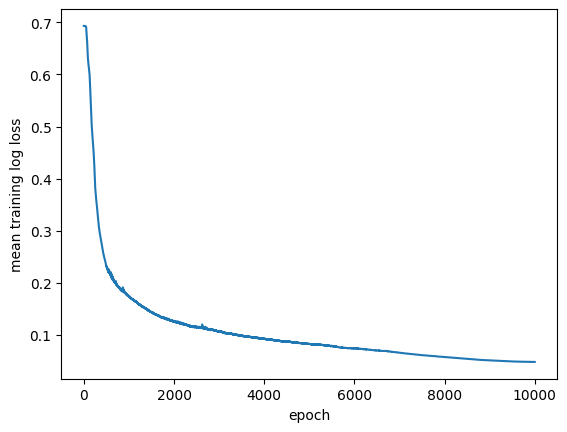

In [7]:
plt.plot(seed_result["out"]["epoch_losses"][0:])
plt.xlabel("epoch")
plt.ylabel("mean training log loss")
out = seed_result["out"]
ckpts = out["checkpoint_snapshots"]
opt_ckpts = out["optimizer_snapshots"]
tree = seed_result["tree"]
print(f"{len(ckpts)} model snapshots, {len(opt_ckpts)} optimizer snapshots")
print("optimizer groups:", out["optimizer_group_names"])
for _name, _lrs in out["lr_history_by_group"].items():
    print(f"  {_name:6s} lr {_lrs[0]:.4g} -> {_lrs[-1]:.4g}")

out = seed_result["out"]
ckpts = out["checkpoint_snapshots"]
tree = seed_result["tree"]

## Scatter plot of norm - Cosine sim of first layer neurons and other visualisations

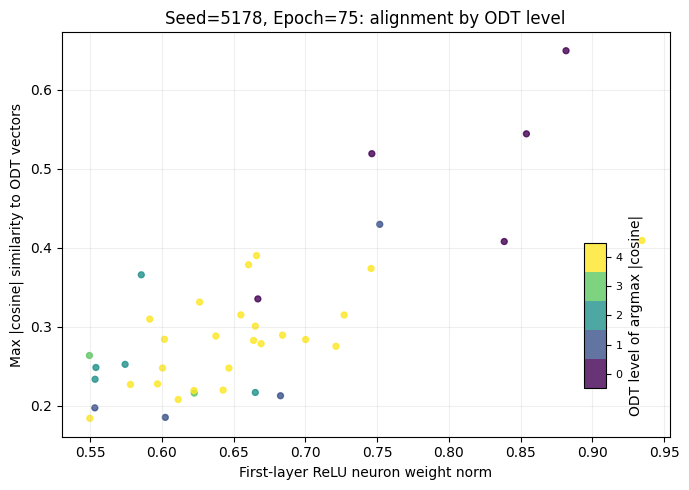

In [16]:

from layer_lenses.relu_analysis import plot_first_layer_odt_alignment


EPOCH = list(ckpts.keys())[75]  # choose from available checkpoints

alignment, fig, ax = plot_first_layer_odt_alignment(
    state_dict=ckpts[EPOCH],
    tree=tree,
    depth=DEPTH,
    epoch=EPOCH,
    seed=SEED,
)
plt.show()

# Keep these names available for downstream scratch cells.
first_layer_wts = alignment["first_layer_wts"]
odt_wts = alignment["odt_wts"]
row_norms = alignment["row_norms"]
cos = alignment["cos"]
abs_cos = alignment["abs_cos"]
max_abs_cos = alignment["max_abs_cos"]
closest_odt = alignment["closest_odt"]
closest_odt_np = alignment["closest_odt_np"]
node_level = alignment["node_level"]

state = ckpts[EPOCH]
HIDDEN_WEIGHTS = [
    state[f"hidden_layers.{layer_idx}.weight"].detach().cpu()
    for layer_idx in range(len(HIDDEN_DIMS))
]
W0 = HIDDEN_WEIGHTS[0]
Wout = state["output_layer.weight"].detach().cpu()



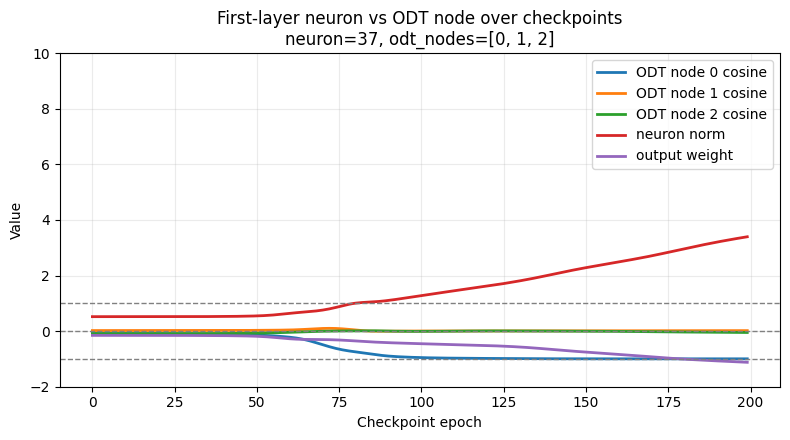

In [17]:
FIRST_LAYER_NEURON_ID = [37]
ODT_INTERNAL_NODE_ID = [0,1,2]
START_EPOCH_PLOT_IDX = 0
END_EPOCH_PLOT_IDX = 200



neuron_ids = list(FIRST_LAYER_NEURON_ID)
odt_node_ids = list(ODT_INTERNAL_NODE_ID)

if not neuron_ids:
    raise ValueError("FIRST_LAYER_NEURON_ID must not be empty.")
if not odt_node_ids:
    raise ValueError("ODT_INTERNAL_NODE_ID must not be empty.")

first_layer_width = ckpts[0]["hidden_layers.0.weight"].shape[0]
internal_node_count = tree.w_list.shape[0]

for neuron_id in neuron_ids:
    if not (0 <= neuron_id < first_layer_width):
        raise ValueError(
            f"Each FIRST_LAYER_NEURON_ID must be in [0, {first_layer_width - 1}], "
            f"got {neuron_id}."
        )

for odt_node_id in odt_node_ids:
    if not (0 <= odt_node_id < internal_node_count):
        raise ValueError(
            f"Each ODT_INTERNAL_NODE_ID must be in [0, {internal_node_count - 1}], "
            f"got {odt_node_id}."
        )

epochs = sorted(ckpts.keys())[START_EPOCH_PLOT_IDX:END_EPOCH_PLOT_IDX]

odt_vectors = {
    odt_node_id: torch.from_numpy(tree.w_list[odt_node_id]).float()
    for odt_node_id in odt_node_ids
}
odt_norms = {
    odt_node_id: float(torch.norm(vector).clamp_min(1e-12))
    for odt_node_id, vector in odt_vectors.items()
}

fig, axes = plt.subplots(
    nrows=len(neuron_ids),
    ncols=1,
    figsize=(8, 4.5 * len(neuron_ids)),
    sharex=True,
    squeeze=False,
)
axes = axes[:, 0]

for ax, neuron_id in zip(axes, neuron_ids):
    neuron_norms = []
    output_wts = []
    normalized_inner_products = {
        odt_node_id: [] for odt_node_id in odt_node_ids
    }

    for epoch in epochs:
        w = (
            ckpts[epoch]["hidden_layers.0.weight"][neuron_id]
            .detach()
            .cpu()
            .float()
        )
        w_norm = float(torch.norm(w).clamp_min(1e-12))
        neuron_norms.append(w_norm)
        output_wts.append(ckpts[epoch]["output_layer.weight"][0,neuron_id].detach().cpu().float())
        for odt_node_id in odt_node_ids:
            cosine = float(
                torch.dot(w, odt_vectors[odt_node_id])
                / (w_norm * odt_norms[odt_node_id])
            )
            normalized_inner_products[odt_node_id].append(cosine)

    for odt_node_id in odt_node_ids:
        label = (
            "normalized inner product (cosine)"
            if len(odt_node_ids) == 1
            else f"ODT node {odt_node_id} cosine"
        )
        ax.plot(
            epochs,
            normalized_inner_products[odt_node_id],
            linewidth=2.0,
            label=label,
        )

    ax.plot(
        epochs,
        neuron_norms,
        linewidth=2.0,
        label="neuron norm",
    )
    ax.plot(
        epochs,
        output_wts,
        linewidth=2.0,
        label="output weight",
    )
    ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(0.0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(-1.0, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("Value")
    # ax.set_yscale("log")
    ax.set_title(
        "First-layer neuron vs ODT node over checkpoints\n"
        f"neuron={neuron_id}, odt_nodes={odt_node_ids}"
    )
    ax.set_ylim(-2,10)
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Checkpoint epoch")
fig.tight_layout()
plt.show()

In [18]:
components = torch.diag(row_norms) @ cos
max_w, argmax_w = torch.max(cos.abs(), dim=0)
for input_idx in range(components.shape[1]):
    neuron_idx = int(argmax_w[input_idx])
    print(
        input_idx,
        max_w[input_idx],
        argmax_w[input_idx],
        components[neuron_idx].norm(),
    )

0 tensor(0.6498) tensor(37) tensor(0.8604)
1 tensor(0.4297) tensor(31) tensor(0.6332)
2 tensor(0.3654) tensor(3) tensor(0.9041)
3 tensor(0.2847) tensor(21) tensor(0.4875)
4 tensor(0.2522) tensor(35) tensor(0.2950)
5 tensor(0.2525) tensor(27) tensor(0.4885)
6 tensor(0.3657) tensor(6) tensor(0.4255)
7 tensor(0.1948) tensor(17) tensor(0.5402)
8 tensor(0.1905) tensor(7) tensor(0.6136)
9 tensor(0.2364) tensor(7) tensor(0.6136)
10 tensor(0.2915) tensor(20) tensor(0.4246)
11 tensor(0.2634) tensor(0) tensor(0.2530)
12 tensor(0.2158) tensor(4) tensor(0.3166)
13 tensor(0.2167) tensor(8) tensor(0.3729)
14 tensor(0.2377) tensor(9) tensor(0.4891)
15 tensor(0.3737) tensor(7) tensor(0.6136)
16 tensor(0.3900) tensor(17) tensor(0.5402)
17 tensor(0.3149) tensor(29) tensor(0.4927)
18 tensor(0.2497) tensor(21) tensor(0.4875)
19 tensor(0.2881) tensor(10) tensor(0.4520)
20 tensor(0.3096) tensor(13) tensor(0.4522)
21 tensor(0.2972) tensor(37) tensor(0.8604)
22 tensor(0.3006) tensor(20) tensor(0.4246)
23 tens

Visible edges: 2974 / 3240
First-layer aligned nodes: 0 / 40


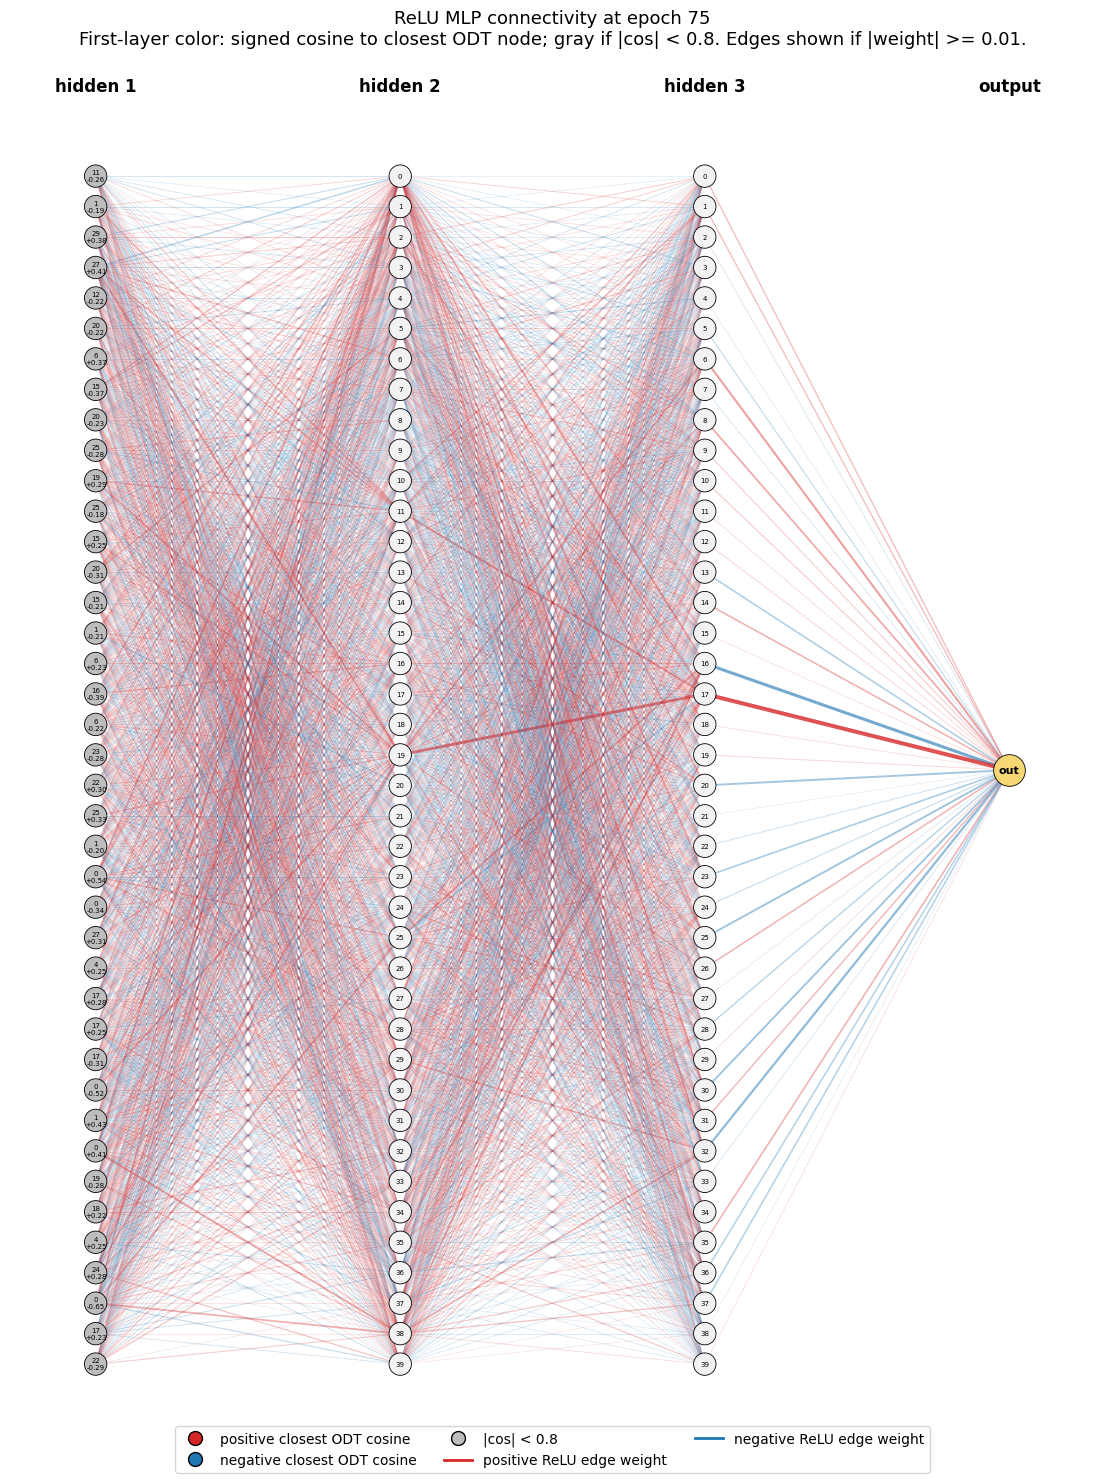

In [19]:
from layer_lenses.relu_analysis import plot_layered_relu_graph

# Layered ReLU graph at a chosen snapshot epoch.
ALIGNMENT_ABS_THRESHOLD = 0.8
EDGE_ABS_THRESHOLD = 0.01  # tune this; increase if graph is too dense
FIGSIZE = (14, 18)

# One mask per hidden layer; edit individual entries to select nodes.
NODE_MASK = [np.ones(width, dtype=bool) for width in HIDDEN_DIMS]

graph_alignment, visible_edges, graph_fig, graph_ax = plot_layered_relu_graph(
    state_dict=state,
    tree=tree,
    depth=DEPTH,
    epoch=EPOCH,
    node_mask=NODE_MASK,
    alignment_abs_threshold=ALIGNMENT_ABS_THRESHOLD,
    edge_abs_threshold=EDGE_ABS_THRESHOLD,
    figsize=FIGSIZE,
    require_both_edge_endpoints_selected=True,
)
plt.show()

## Compute train and test performance

In [20]:

from layer_lenses.relu_analysis import collect_start_end_metrics

rows = collect_start_end_metrics(seed_result)
metrics_table = pd.DataFrame(rows).sort_values(["timepoint"]).reset_index(drop=True)
display(metrics_table)

,timepoint,epoch,train_log_loss,test_error
0,end,10000,0.047264,0.017007
1,start,0,0.693162,0.500519


## Replay one epoch from a snapshot (usage)

`replay_epoch_from_snapshot` restores the model and optimizer to their state at the start of
`REPLAY_EPOCH`, re-runs that epoch's mini-batches, and records per step: the mini-batch
gradient the optimizer consumed, the resulting parameter update, the Adam moments and the
per-coordinate step size `lr / (sqrt(v_hat) + eps)`, and optionally the population gradient
over the full training set at the step's starting parameters. If `REPLAY_EPOCH + 1` is also a
snapshot, `replay["verification"]` reports the max deviation of the replayed end-of-epoch
parameters from the stored ones (should be 0).

In [21]:
REPLAY_EPOCH = EPOCH  # must be in SNAPSHOT_EPOCHS and < TOTAL_EPOCHS

replay = replay_epoch_from_snapshot(
    seed_result,
    REPLAY_EPOCH,
    data=data,
    verify_against_next_snapshot=True,
    record_optimizer_state=True,
    record_full_data_gradient=True,  # population gradient at each step's starting parameters
)
print("lr in force:", replay["lr_by_group"], "| steps:", replay["num_steps"])
print("verification vs next snapshot:", replay["verification"])

summary = epoch_replay_summary_table(replay)
summary.head(100)


lr in force: {'sgd': 0.019997363087071} | steps: 100
verification vs next snapshot: {'next_epoch': 76, 'max_abs_param_diff': {'hidden_layers.0.weight': 0.0, 'hidden_layers.1.weight': 0.0, 'hidden_layers.2.weight': 0.0, 'output_layer.weight': 0.0}, 'max_abs_param_diff_overall': 0.0, 'max_abs_optimizer_state_diff': 0.0}


,step,batch_loss,lr,grad_norm,update_norm,cos_update_grad,cos_update_epoch_delta,cos_grad_epoch_delta,cum_update_norm,full_grad_norm,cos_grad_full_grad,cos_update_full_grad
0,0,0.662547,0.019997,0.026792,0.002070,-0.486186,0.880962,-0.340647,0.002070,0.009428,0.346304,-0.883245
1,1,0.664324,0.019997,0.026975,0.002066,-0.487650,0.878824,-0.322611,0.004102,0.009431,0.324020,-0.880232
2,2,0.660660,0.019997,0.028214,0.002114,-0.558718,0.865694,-0.348569,0.006157,0.009436,0.354186,-0.867267
3,3,0.658998,0.019997,0.026659,0.002118,-0.508820,0.864713,-0.345378,0.008200,0.009444,0.344513,-0.863481
4,4,0.663471,0.019997,0.027313,0.002139,-0.530754,0.861684,-0.356760,0.010251,0.009452,0.359446,-0.858539
...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,0.661221,0.019997,0.026772,0.002198,-0.458027,0.873485,-0.313050,0.184227,0.009910,0.315144,-0.871517
96,96,0.656965,0.019997,0.030419,0.002211,-0.499650,0.871651,-0.327144,0.186136,0.009917,0.335274,-0.871293
97,97,0.661165,0.019997,0.027468,0.002220,-0.521955,0.873389,-0.373195,0.188063,0.009922,0.377857,-0.873189
98,98,0.655916,0.019997,0.027948,0.002204,-0.478124,0.878399,-0.341668,0.189991,0.009928,0.352189,-0.879711


In [22]:

# Per-step tensors for one parameter, shape (num_steps, *param_shape):
grads_l0 = epoch_replay_parameter_series(replay, "grad", "hidden_layers.0.weight")
updates_l0 = epoch_replay_parameter_series(replay, "update", "hidden_layers.0.weight")
pop_grads_l0 = epoch_replay_parameter_series(replay, "full_grad", "hidden_layers.0.weight")

In [25]:
neuron_id = 37
total_update =updates_l0[:,neuron_id,:].sum(axis=0)
total_grads_over_steps = grads_l0[:,neuron_id,:].sum(axis=0)
total_pop_grads_over_steps = pop_grads_l0[:,neuron_id,:].sum(axis=0)

after = ckpts[REPLAY_EPOCH+1]["hidden_layers.0.weight"][neuron_id,:]
before = ckpts[REPLAY_EPOCH]["hidden_layers.0.weight"][neuron_id,:]
epoch_delta =  after - before

print("Cos between total_update and epoch_delta:", total_update@epoch_delta/(total_update.norm()*epoch_delta.norm()))
print("total_update norm:", total_update.norm(), "\t epoch_delta norm:", epoch_delta.norm(), "\nparam norm before:", before.norm(), "\t param norm after:", after.norm())

print("Cos between total_update and odt_wts[0]:", total_update @ odt_wts[0]/(total_update.norm()*odt_wts[0].norm()))
print("Cos between total_grads_over_steps and odt_wts[0]:", total_grads_over_steps @ odt_wts[0]/(total_grads_over_steps.norm()*odt_wts[0].norm()))
print("Cos between total_pop_grads_over_steps and odt_wts[0]:",   total_pop_grads_over_steps @ odt_wts[0]/(total_pop_grads_over_steps.norm()*odt_wts[0].norm()))
print("Cos between param before epoch and odt_wts[0]:",   before @ odt_wts[0]/(before.norm()*odt_wts[0].norm()))
print("Cos between param after epoch and odt_wts[0]:",   after @ odt_wts[0]/(after.norm()*odt_wts[0].norm()))
print("================================")
for step in range(replay["num_steps"]):
    step_grad = grads_l0[step,neuron_id,:]
    step_update = updates_l0[step,neuron_id,:]
    pop_grad_at_step = pop_grads_l0[step,neuron_id,:]

    print(
        f"step {step:4d}: \n"
        f"grad norm {step_grad.norm():.4g}, \t\t "
        f"update norm {step_update.norm():.4g}, \t\t"
        f"pop_grad norm {pop_grad_at_step.norm():.4g} \n"
        f"cos(grad, update) {float(torch.dot(step_grad, step_update)/(step_grad.norm()*step_update.norm())):.4g}, \t"
        f"cos(grad, pop_grad) {float(torch.dot(step_grad, pop_grad_at_step)/(step_grad.norm()*pop_grad_at_step.norm())):.4g}, \n"
        f"cos(grad, odt_w[0]) {float(torch.dot(step_grad, odt_wts[0])/(step_grad.norm()*odt_wts[0].norm())):.4g}, \t"
        f"cos(update, odt_w[0]) {float(torch.dot(step_update, odt_wts[0])/(step_update.norm()*odt_wts[0].norm())):.4g}, \t"
        f"cos(pop_grad, odt_w[0]) {float(torch.dot(pop_grad_at_step, odt_wts[0])/(pop_grad_at_step.norm()*odt_wts[0].norm())):.4g}, "
    )
    print("================================")



Cos between total_update and epoch_delta: tensor(1.0000)
total_update norm: tensor(0.0650) 	 epoch_delta norm: tensor(0.0650) 
param norm before: tensor(0.8817) 	 param norm after: tensor(0.9111)
Cos between total_update and odt_wts[0]: tensor(-0.6295)
Cos between total_grads_over_steps and odt_wts[0]: tensor(0.6297)
Cos between total_pop_grads_over_steps and odt_wts[0]: tensor(0.6304)
Cos between param before epoch and odt_wts[0]: tensor(-0.6498)
Cos between param after epoch and odt_wts[0]: tensor(-0.6737)
step    0: 
grad norm 0.009569, 		 update norm 0.0007405, 		pop_grad norm 0.003308 
cos(grad, update) -0.4994, 	cos(grad, pop_grad) 0.3648, 
cos(grad, odt_w[0]) 0.1049, 	cos(update, odt_w[0]) -0.5258, 	cos(pop_grad, odt_w[0]) 0.6316, 
step    1: 
grad norm 0.01051, 		 update norm 0.0007381, 		pop_grad norm 0.003307 
cos(grad, update) -0.4667, 	cos(grad, pop_grad) 0.2985, 
cos(grad, odt_w[0]) 0.2108, 	cos(update, odt_w[0]) -0.5348, 	cos(pop_grad, odt_w[0]) 0.6324, 
step    2: 
grad 

In [ ]:
print(replay.keys())
print(replay["steps"][0].keys())
print(replay["steps"][0]["optimizer_state_after"]["hidden_layers.0.weight"]["momentum_buffer"].shape)

dict_keys(['epoch', 'lr', 'lr_by_group', 'optimizer', 'optimizer_group_names', 'parameter_groups', 'betas', 'eps', 'weight_decay', 'momentum', 'shuffle_each_epoch', 'num_steps', 'params_before', 'params_after', 'steps', 'verification'])
dict_keys(['step', 'batch_start', 'batch_end', 'params_before', 'full_grad', 'batch_loss', 'grad', 'update', 'optimizer_state_after'])
torch.Size([40, 100])


## Per-optimizer-group readout for sgd_adam

For a `"sgd_adam"` run, `replay["parameter_groups"]` names which parameters each optimizer
owns. Passing one group to `epoch_replay_summary_table` restricts every column to that group,
which is how to compare the SGD-trained early layers against the AdamW-trained later ones on
the same epoch: `cos_update_full_grad` says how closely each group's actual step tracks the
population gradient.

In [ ]:
for _group, _names in replay["parameter_groups"].items():
    _table = epoch_replay_summary_table(replay, parameter_names=_names)
    _cols = [c for c in ["step", "grad_norm", "update_norm", "cos_update_grad",
                         "cos_update_full_grad", "cos_update_epoch_delta"]
             if c in _table.columns]
    print(f"\n=== {_group}: {_names} ===")
    print(_table[_cols].head(8).to_string(index=False))